<a href="https://colab.research.google.com/github/sudeep-bhulla/ADA-LAB/blob/main/SML_Lab_Programs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# program 1 - q2,q3, iqr
import numpy as np
prices = ([250000,300000,320000,350000,375000,400000,420000,450000,480000,500000,550000,600000])

q1 = np.percentile(prices,25)
q3 = np.percentile(prices, 75)
iqr = (q3-q1)

print(q1,q3,iqr)


342500.0 485000.0 142500.0


RepeatPurchase  No  Yes  yes
Satisfaction                
High             0    2    1
Low              4    0    0
Medium           1    2    0


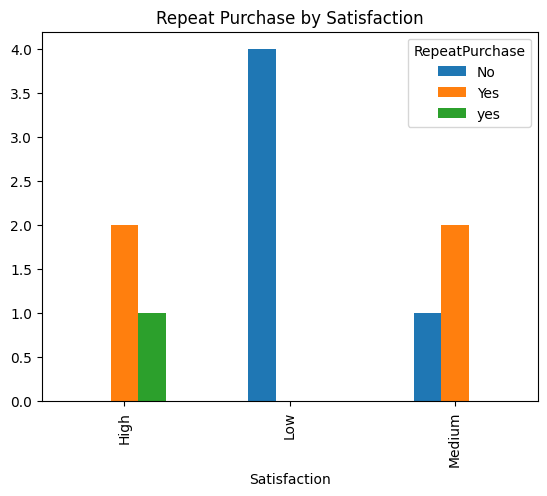

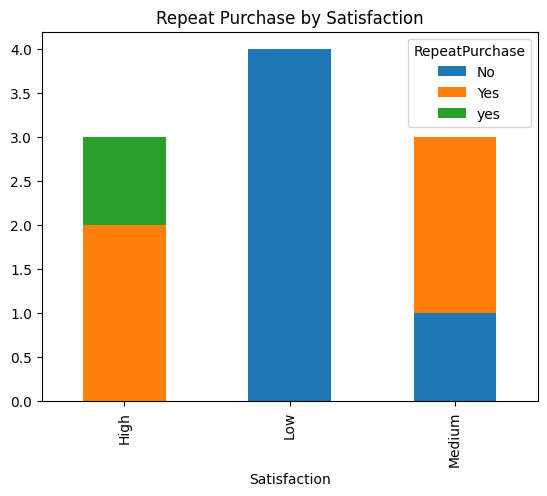

In [ ]:
# program 2 - bar chart vs stacked bar chart
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    'Satisfaction': ['Low','Medium','High','Medium','Low','High','High','Low','Medium','Low'],
    'RepeatPurchase':['No','No','yes','Yes','No','Yes','Yes','No','Yes','No']
})

tab = pd.crosstab(df.Satisfaction, df.RepeatPurchase)
print(tab)


tab.plot(kind='bar')
plt.title('Repeat Purchase by Satisfaction')
plt.show()

tab.plot(kind='bar',stacked= True)
plt.title('Repeat Purchase by Satisfaction')
plt.show()

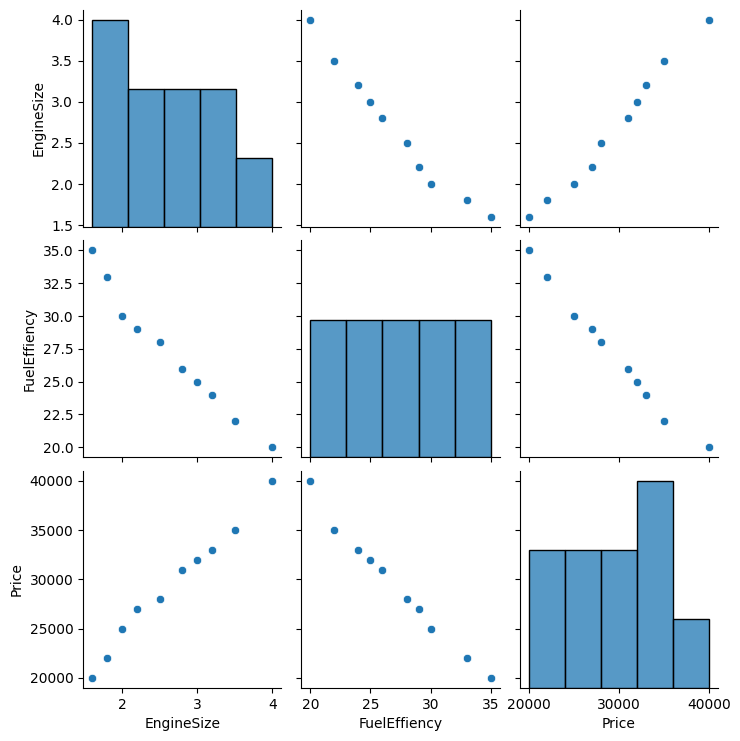

              EngineSize  FuelEffiency     Price
EngineSize      1.000000     -0.985854  0.992210
FuelEffiency   -0.985854      1.000000 -0.993457
Price           0.992210     -0.993457  1.000000


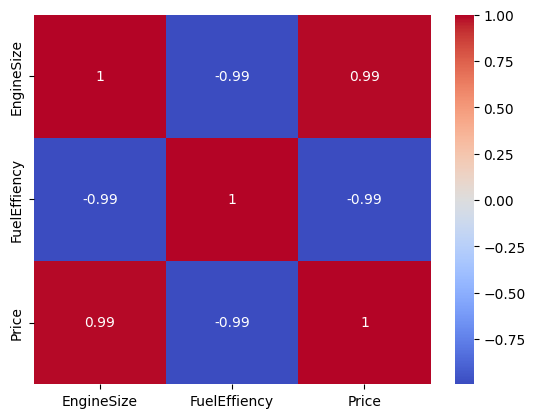

In [ ]:
# program 3 - relation b/w engine size, fuel efficieny and price

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


df = pd.DataFrame({
    'EngineSize': [1.6,2,2.5,3,3.5,4,2.2,1.8,3.2,2.8],
    'FuelEffiency': [35,30,28,25,22,20,29,33,24,26],
    'Price':  [20000,25000,28000,32000,35000,40000,27000,22000,33000,31000]


})

sns.pairplot(df)
plt.show()

corr =df.corr()
print(corr)

sns.heatmap(corr, annot=True,cmap='coolwarm')
plt.show()

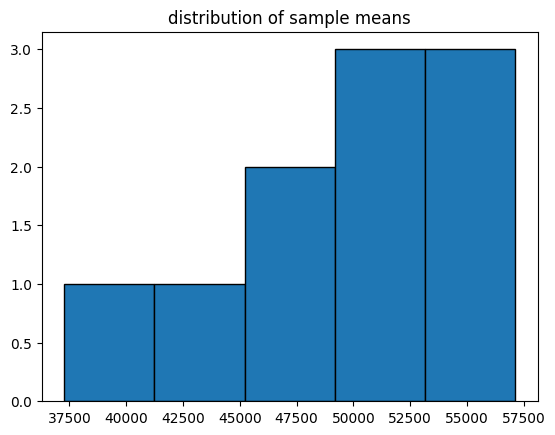

[np.float64(50407.49240985955), np.float64(47441.48917339016), np.float64(46359.98208875922), np.float64(51123.35940175571), np.float64(54792.45402080486), np.float64(42987.13036469506), np.float64(53695.91997831957), np.float64(57123.356348168345), np.float64(51519.533296452275), np.float64(37272.40519664386)]


In [ ]:
# program 4 - distribution of sample means by random sampling


import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

population = np.random.exponential(50000,10000)

means=[]
for i in range(10):
  sample = np.random.choice(population,50,replace = False)
  means.append(np.mean(sample))


plt.hist(means,bins=5,edgecolor='black')
plt.title("distribution of sample means")
plt.show()


print(means)



In [ ]:
# program 5 one sample t-test


from scipy import stats
import math

mean, std, n = 8, 2, 20
t = mean / (std / math.sqrt(n))
p = 2 * (1 - stats.t.cdf(abs(t), n-1))

print("t =", round(t, 3))
print("p =", round(p, 5))

if p < 0.05:
    print("Reject H0")
else:
    print("Fail to reject H0")

t = 17.889
p = 0.0
Reject H0


In [ ]:

# Program 6: Two-Proportion Z-Test

from statsmodels.stats.proportion import proportions_ztest

successes = [120, 150]
total = [1000, 1200]
alpha = 0.05

z, p = proportions_ztest(successes, total)

print(f"Z-statistic: {z:.3f}")
print(f"P-value: {p:.5f}")

if p < alpha:
    print("Reject the null hypothesis: There is a significant difference in conversion rates between A and B.")
else:
    print("Fail to reject the null hypothesis: No significant difference in conversion rates between A and B.")


Z-statistic: -0.356
P-value: 0.72193
Fail to reject the null hypothesis: No significant difference in conversion rates between A and B.


In [ ]:

# Program 7: Two-Sample T-Test

from scipy import stats
import math

mean_A, std_A, n_A = 1000, 100, 30
mean_B, std_B, n_B = 950, 120, 30
alpha = 0.05

a = std_A**2 / n_A
b = std_B**2 / n_B

t_stat = (mean_A - mean_B) / math.sqrt(a + b)
df = (a + b)**2 / (a**2 / (n_A - 1) + b**2 / (n_B - 1))
p_value = 2 * (1 - stats.t.cdf(abs(t_stat), df=df))

print(f"T-statistic: {t_stat:.3f}")
print(f"Degrees of freedom: {df:.2f}")
print(f"P-value: {p_value:.5f}")

if p_value < alpha:
    print("Reject the null hypothesis: There is a significant difference between the average sales of the two stores.")
else:
    print("Fail to reject the null hypothesis: No significant difference between the average sales of the two stores.")


T-statistic: 1.753
Degrees of freedom: 56.17
P-value: 0.08502
Fail to reject the null hypothesis: No significant difference between the average sales of the two stores.


In [ ]:

# Program 8: Multiple Linear Regression

import pandas as pd
import statsmodels.formula.api as smf

data = {
    'Salary': [40000, 50000, 60000, 45000, 55000, 65000, 48000, 58000, 70000, 62000],
    'Education': ['High School', "Bachelor's", "Master's", 'High School', "Bachelor's", "Master's", 'High School', "Bachelor's", "Master's", "Bachelor's"],
    'Experience': [2, 5, 7, 3, 6, 8, 4, 5, 9, 6]
}

df = pd.DataFrame(data)

model = smf.ols(
    'Salary ~ Experience + C(Education, Treatment(reference="High School"))',
    data=df
).fit()

print(model.summary())


                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.928
Model:                            OLS   Adj. R-squared:                  0.892
Method:                 Least Squares   F-statistic:                     25.72
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           0.000799
Time:                        03:12:17   Log-Likelihood:                -92.071
No. Observations:                  10   AIC:                             192.1
Df Residuals:                       6   BIC:                             193.4
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                                                     coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.992
Model:                            OLS   Adj. R-squared:                  0.990
Method:                 Least Squares   F-statistic:                     458.5
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           3.78e-08
Time:                        03:12:17   Log-Likelihood:                -105.38
No. Observations:                  10   AIC:                             216.8
Df Residuals:                       7   BIC:                             217.7
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -2.557e+05   4.11e+04     -6.217      0.0

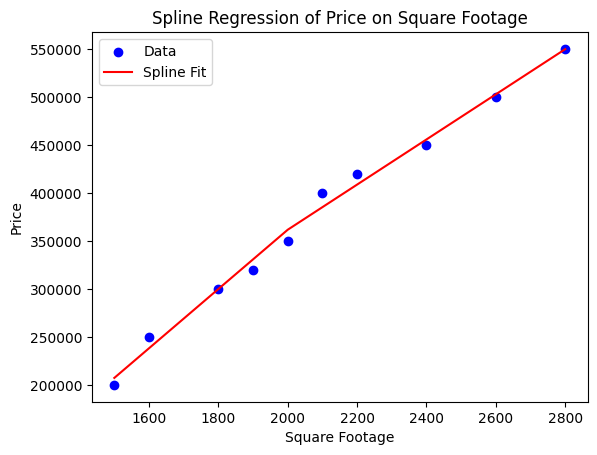

In [ ]:

# Program 9: Spline Regression

import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

data = {
    'Price': [200000, 250000, 300000, 320000, 350000, 400000, 420000, 450000, 500000, 550000],
    'SqFt': [1500, 1600, 1800, 1900, 2000, 2100, 2200, 2400, 2600, 2800]
}

df = pd.DataFrame(data)
df['sqft_knot'] = np.maximum(0, df['SqFt'] - 2000)

X = sm.add_constant(df[['SqFt', 'sqft_knot']])
y = df['Price']

model = sm.OLS(y, X).fit()
print(model.summary())

plt.scatter(df['SqFt'], y, color='blue', label='Data')
plt.plot(df['SqFt'], model.predict(X), color='red', label='Spline Fit')
plt.xlabel('Square Footage')
plt.ylabel('Price')
plt.title('Spline Regression of Price on Square Footage')
plt.legend()
plt.show()


In [ ]:

# Program 10: Poisson Regression

import numpy as np

intercept = 2.5
coef_age = -0.03
coef_condition = 0.5
age = 60

# With chronic condition
log_lambda = intercept + coef_age * age + coef_condition
visits = np.exp(log_lambda)
print(f"Expected number of visits (with chronic condition): {visits:.2f}")

# Without chronic condition
log_lambda = intercept + coef_age * age
visits = np.exp(log_lambda)
print(f"Expected number of visits (without chronic condition): {visits:.2f}")


Expected number of visits (with chronic condition): 3.32
Expected number of visits (without chronic condition): 2.01


In [ ]:

# Program 11: One-Sample T-Test

from scipy import stats
import math

old_mean = 200
sample_mean = 190
sample_std = 15
n = 40
alpha = 0.05

t = (sample_mean - old_mean) / (sample_std / math.sqrt(n))
p = stats.t.cdf(t, df=n - 1)

print(f"T-statistic: {t:.3f}")
print(f"P-value: {p:.5f}")

if p < alpha:
    print("Reject the null hypothesis: The new recipe has significantly fewer calories.")
else:
    print("Fail to reject the null hypothesis: No significant difference in calories.")

T-statistic: -4.216
P-value: 0.00007
Reject the null hypothesis: The new recipe has significantly fewer calories.
